
# MINERÍA DE DATOS — RED SALUD INTEGRAL CARAZO

## Objetivo
Desarrollar y evaluar tres modelos predictivos de inasistencia a citas médicas, asociados a tres KPI de desempeño.

## PASO 1. Verificación de las fuentes de información

Se comparan los registros originales, el conjunto apto de Calidad y el dataset predictivo de SQL Server para establecer la correspondencia entre sus identificadores.

No se modifican los datos originales ni se entrena ningún modelo durante esta verificación.


In [1]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 1. CONCILIACIÓN DE FUENTES
# ============================================================

import sys
import pandas as pd

from pathlib import Path
from datetime import datetime, timezone
from sqlalchemy import text
from dotenv import load_dotenv
from IPython.display import display


# ============================================================
# 1. LOCALIZAR PROYECTO
# ============================================================

rutas = [
    Path.cwd(),
    Path.cwd().parent,
    Path.cwd() / "RedSaludCarazo_proyecto_base"
]

proyecto = next(
    (
        ruta for ruta in rutas
        if (ruta / "src" / "database.py").is_file()
    ),
    None
)

if proyecto is None:
    raise FileNotFoundError(
        "No se encontró la carpeta del proyecto."
    )

sys.path.insert(0, str(proyecto / "src"))

load_dotenv(proyecto / ".env", override=True)

from database import engine_sqlserver

engine = engine_sqlserver()


# ============================================================
# 2. CONSULTAR LAS TABLAS DE SQL SERVER
# ============================================================

with engine.connect() as conexion:

    base = conexion.execute(
        text("SELECT DB_NAME()")
    ).scalar_one()

    raw = pd.read_sql_query(
        text("""
            SELECT id_raw, id_cita, fecha_cita
            FROM dbo.raw_cita
        """),
        conexion
    )

    predictivo = pd.read_sql_query(
        text("""
            SELECT id_cita, fecha_cita
            FROM dbo.dm_dataset_prediccion
        """),
        conexion
    )

if base != "RedSaludCarazoDW_V2":
    raise ValueError(
        f"Base inesperada: {base}"
    )


# ============================================================
# 3. RECUPERAR EL ÚLTIMO DATASET APTO
# ============================================================

carpeta_limpieza = (
    proyecto
    / "resultados_jupyter"
    / "optativo_III"
    / "limpieza"
)

archivos = list(
    carpeta_limpieza.glob("dataset_apto_*.csv")
)

if not archivos:
    raise FileNotFoundError(
        "No se encontró el dataset apto de Calidad."
    )

archivo_apto = max(
    archivos,
    key=lambda ruta: ruta.stat().st_mtime
)

apto = pd.read_csv(
    archivo_apto,
    dtype={"id_cita": "string"},
    low_memory=False
)


# ============================================================
# 4. NORMALIZAR IDENTIFICADORES
# ============================================================

def normalizar_ids(serie):
    return (
        serie.astype("string")
        .str.strip()
        .str.upper()
        .replace("", pd.NA)
    )


for tabla in [raw, apto, predictivo]:
    tabla["ID_COMPARACION"] = normalizar_ids(
        tabla["id_cita"]
    )

    if tabla["ID_COMPARACION"].isna().any():
        raise ValueError(
            "Se detectaron identificadores vacíos."
        )

# En origen existen identificadores repetidos.
# En los conjuntos apto y predictivo esperamos
# un identificador único por cita.

for nombre, tabla in [
    ("APTO", apto),
    ("PREDICTIVO", predictivo)
]:
    if tabla["ID_COMPARACION"].duplicated().any():
        raise ValueError(
            f"Hay identificadores repetidos en {nombre}."
        )


# ============================================================
# 5. COMPARAR LOS IDENTIFICADORES
# ============================================================

ids_raw = set(raw["ID_COMPARACION"])
ids_apto = set(apto["ID_COMPARACION"])
ids_predictivo = set(predictivo["ID_COMPARACION"])

ambos = ids_apto & ids_predictivo

solo_apto = ids_apto - ids_predictivo
solo_predictivo = ids_predictivo - ids_apto

detalle = pd.DataFrame({
    "id_cita": sorted(
        ids_raw | ids_apto | ids_predictivo
    )
})

detalle["En_raw"] = detalle["id_cita"].isin(ids_raw)

detalle["En_apto"] = detalle["id_cita"].isin(ids_apto)

detalle["En_predictivo"] = (
    detalle["id_cita"].isin(ids_predictivo)
)

detalle["Situacion"] = "REVISAR"

detalle.loc[
    detalle["En_apto"] & detalle["En_predictivo"],
    "Situacion"
] = "EN_AMBOS"

detalle.loc[
    detalle["En_apto"] & ~detalle["En_predictivo"],
    "Situacion"
] = "SOLO_APTO"

detalle.loc[
    ~detalle["En_apto"] & detalle["En_predictivo"],
    "Situacion"
] = "SOLO_PREDICTIVO"

detalle.loc[
    ~detalle["En_apto"] & ~detalle["En_predictivo"],
    "Situacion"
] = "SOLO_ORIGEN"


# ============================================================
# 6. CONSTRUIR RESUMEN
# ============================================================

resumen = pd.DataFrame([
    {
        "Comprobacion": "Registros originales",
        "Cantidad": len(raw)
    },
    {
        "Comprobacion": "IDs distintos en origen",
        "Cantidad": len(ids_raw)
    },
    {
        "Comprobacion": "Registros aptos",
        "Cantidad": len(apto)
    },
    {
        "Comprobacion": "Registros predictivos",
        "Cantidad": len(predictivo)
    },
    {
        "Comprobacion": "IDs presentes en ambos conjuntos",
        "Cantidad": len(ambos)
    },
    {
        "Comprobacion": "IDs solo en conjunto apto",
        "Cantidad": len(solo_apto)
    },
    {
        "Comprobacion": "IDs solo en predictivo",
        "Cantidad": len(solo_predictivo)
    }
])


# ============================================================
# 7. PRESENTAR EVIDENCIAS
# ============================================================

print("=" * 70)
print("MINERÍA DE DATOS")
print("PASO 1. CONCILIACIÓN DE FUENTES")
print("=" * 70)

print("\nBase de datos:", base)
print("Dataset apto:", archivo_apto.name)

print("\n1. RESUMEN DE CORRESPONDENCIA")
display(resumen)

print("\n2. DISTRIBUCIÓN DE IDENTIFICADORES")
display(
    detalle["Situacion"]
    .value_counts()
    .rename_axis("Situacion")
    .reset_index(name="Cantidad")
)

print("\n3. EJEMPLOS DE DIFERENCIAS")

display(
    detalle.loc[
        detalle["Situacion"].isin(
            ["SOLO_APTO", "SOLO_PREDICTIVO"]
        )
    ].head(20)
)

if len(solo_predictivo) == 0:
    print(
        "\nTodos los IDs predictivos aparecen "
        "en el conjunto apto."
    )
else:
    print(
        "\nATENCIÓN: existen IDs predictivos "
        "que no están en el conjunto apto."
    )

print(
    "\nEsta comparación identifica diferencias, "
    "pero no demuestra todavía sus causas."
)


# ============================================================
# 8. GUARDAR EVIDENCIAS
# ============================================================

carpeta_mineria = (
    proyecto
    / "resultados_jupyter"
    / "mineria"
    / "conciliacion"
)

carpeta_mineria.mkdir(
    parents=True,
    exist_ok=True
)

fecha = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%SZ")

resumen.to_csv(
    carpeta_mineria / f"resumen_fuentes_{fecha}.csv",
    index=False,
    encoding="utf-8-sig"
)

detalle.to_csv(
    carpeta_mineria / f"detalle_correspondencia_{fecha}.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nEvidencias guardadas en:", carpeta_mineria)
print("PASO 1 FINALIZADO")
print("No se modificó SQL Server.")


MINERÍA DE DATOS
PASO 1. CONCILIACIÓN DE FUENTES

Base de datos: RedSaludCarazoDW_V2
Dataset apto: dataset_apto_20261024T210524Z.csv

1. RESUMEN DE CORRESPONDENCIA


,Comprobacion,Cantidad
0,Registros originales,10080
1,IDs distintos en origen,10000
2,Registros aptos,9076
3,Registros predictivos,8996
4,IDs presentes en ambos conjuntos,8996
5,IDs solo en conjunto apto,80
6,IDs solo en predictivo,0



2. DISTRIBUCIÓN DE IDENTIFICADORES


,Situacion,Cantidad
0,EN_AMBOS,8996
1,SOLO_ORIGEN,924
2,SOLO_APTO,80



3. EJEMPLOS DE DIFERENCIAS


,id_cita,En_raw,En_apto,En_predictivo,Situacion
91,RSV2-000092,True,True,False,SOLO_APTO
167,RSV2-000168,True,True,False,SOLO_APTO
475,RSV2-000476,True,True,False,SOLO_APTO
662,RSV2-000663,True,True,False,SOLO_APTO
825,RSV2-000826,True,True,False,SOLO_APTO
852,RSV2-000853,True,True,False,SOLO_APTO
855,RSV2-000856,True,True,False,SOLO_APTO
1283,RSV2-001284,True,True,False,SOLO_APTO
1339,RSV2-001340,True,True,False,SOLO_APTO
1354,RSV2-001355,True,True,False,SOLO_APTO



Todos los IDs predictivos aparecen en el conjunto apto.

Esta comparación identifica diferencias, pero no demuestra todavía sus causas.

Evidencias guardadas en: c:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados_jupyter\mineria\conciliacion
PASO 1 FINALIZADO
No se modificó SQL Server.



## PASO 2. Investigación de diferencias entre conjuntos

### Objetivo
Identificar los 80 registros que aparecen en el conjunto apto de Calidad, pero no en el dataset predictivo.

### Verificaciones
- Comparar sus identificadores con los grupos duplicados del origen.
- Determinar si las copias originales eran idénticas o tenían diferencias.
- Comprobar qué registros se conservaron en el conjunto apto.
- Contrastar los registros exclusivos del origen con los casos en cuarentena.

### Evidencia
Se generan archivos CSV con los identificadores investigados y los resultados de la conciliación.

Esta comparación no modifica SQL Server ni demuestra por sí sola las reglas internas de transformación del dataset predictivo.


In [2]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 2. INVESTIGACIÓN DE LOS 80 IDENTIFICADORES
# ============================================================

import pandas as pd
from pathlib import Path
from sqlalchemy import text
from datetime import datetime, timezone
from IPython.display import display


# ============================================================
# 1. RECUPERAR LOS DATOS ORIGINALES COMPLETOS
# ============================================================

with engine.connect() as conexion:
    raw_completo = pd.read_sql_query(
        text("SELECT * FROM dbo.raw_cita"),
        conexion
    )

raw_completo["ID_COMPARACION"] = normalizar_ids(
    raw_completo["id_cita"]
)

# Variables existentes del PASO 1:
# apto, predictivo, archivo_apto, proyecto


# ============================================================
# 2. IDENTIFICAR GRUPOS REPETIDOS DEL ORIGEN
# ============================================================

frecuencias_raw = (
    raw_completo["ID_COMPARACION"]
    .dropna()
    .value_counts()
)

ids_duplicados_raw = set(
    frecuencias_raw[
        frecuencias_raw > 1
    ].index
)

ids_apto_actual = set(
    normalizar_ids(apto["id_cita"]).dropna()
)

ids_predictivo_actual = set(
    normalizar_ids(predictivo["id_cita"]).dropna()
)

ids_solo_apto = (
    ids_apto_actual - ids_predictivo_actual
)

coincidencia_80 = (
    ids_solo_apto == ids_duplicados_raw
)

print("=" * 70)
print("PASO 2. INVESTIGACIÓN DE DIFERENCIAS")
print("=" * 70)

print("\n1. COMPARACIÓN DE IDENTIFICADORES")

print(
    "Grupos de IDs repetidos en origen:",
    len(ids_duplicados_raw)
)

print(
    "IDs exclusivos del conjunto apto:",
    len(ids_solo_apto)
)

print(
    "IDs exclusivos del apto que estaban repetidos:",
    len(ids_solo_apto & ids_duplicados_raw)
)

print(
    "¿Coinciden exactamente ambos conjuntos?:",
    coincidencia_80
)


# ============================================================
# 3. ANALIZAR LAS COPIAS ORIGINALES
# ============================================================

columnas_originales = [
    "id_cita",
    "fecha_cita",
    "centro_salud",
    "canal_agendamiento",
    "grupo_edad",
    "especialidad",
    "costo_estimado_usd",
    "espera_dias",
    "recordatorios_enviados",
    "citas_previas_perdidas",
    "tipo_cobertura",
    "sistema_origen",
    "no_asistio",
    "consentimiento_contacto",
    "fecha_carga"
]

faltan = set(columnas_originales) - set(
    raw_completo.columns
)

if faltan:
    raise ValueError(
        f"Faltan columnas: {sorted(faltan)}"
    )

resultados = []

for identificador in sorted(ids_duplicados_raw):

    grupo = raw_completo.loc[
        raw_completo["ID_COMPARACION"]
        == identificador
    ].copy()

    # Contar versiones diferentes del registro
    versiones = len(
        grupo[columnas_originales].drop_duplicates()
    )

    tipo = (
        "COPIAS IDENTICAS"
        if versiones == 1
        else "COPIAS CON DIFERENCIAS"
    )

    filas_aptas = apto.loc[
        normalizar_ids(apto["id_cita"])
        == identificador
    ]

    resultados.append({
        "id_cita": identificador,
        "Filas_en_origen": len(grupo),
        "Versiones_originales": versiones,
        "Tipo_duplicidad": tipo,
        "id_raw_originales": ", ".join(
            grupo["id_raw"].astype(str)
        ),
        "id_raw_conservado_en_apto": (
            ", ".join(
                filas_aptas["id_raw"].astype(str)
            )
            if not filas_aptas.empty
            else "NINGUNO"
        ),
        "En_apto": identificador in ids_apto_actual,
        "En_predictivo": (
            identificador in ids_predictivo_actual
        )
    })

tabla_duplicados = pd.DataFrame(resultados)

print("\n2. ANÁLISIS DE LOS GRUPOS DUPLICADOS")

display(
    tabla_duplicados["Tipo_duplicidad"]
    .value_counts()
    .rename_axis("Tipo")
    .reset_index(name="Grupos")
)

print("\n3. IDENTIFICADORES Y REGISTROS ORIGINALES")

display(tabla_duplicados.head(15))


# ============================================================
# 4. INVESTIGAR LOS 80 IDS SOLO EN EL APTO
# ============================================================

detalle_solo_apto = tabla_duplicados.loc[
    tabla_duplicados["id_cita"].isin(
        ids_solo_apto
    )
].copy()

print("\n4. IDENTIFICADORES EXCLUSIVOS DE CALIDAD")

display(detalle_solo_apto.head(15))

# Identificar grupos repetidos que sí estén
# presentes en el dataset predictivo

duplicados_en_predictivo = (
    ids_duplicados_raw & ids_predictivo_actual
)

print(
    "\nIDs repetidos originalmente que llegaron a Minería:",
    len(duplicados_en_predictivo)
)


# ============================================================
# 5. VERIFICAR LOS REGISTROS EN CUARENTENA
# ============================================================

# Recuperar la bitácora correspondiente a la
# misma ejecución del dataset apto seleccionado.

marca = archivo_apto.stem.replace(
    "dataset_apto_", "", 1
)

ruta_bitacora = (
    archivo_apto.parent
    / f"bitacora_tratamientos_{marca}.csv"
)

if not ruta_bitacora.is_file():
    raise FileNotFoundError(
        f"No se encontró {ruta_bitacora.name}"
    )

bitacora = pd.read_csv(
    ruta_bitacora,
    dtype={"id_cita": "string"},
    low_memory=False
)

bitacora["ID_COMPARACION"] = normalizar_ids(
    bitacora["id_cita"]
)

ids_cuarentena = set(
    bitacora.loc[
        bitacora["Estado_final"]
        == "EN_CUARENTENA_PARA_REVISION",
        "ID_COMPARACION"
    ].dropna()
)

ids_solo_origen = (
    set(raw_completo["ID_COMPARACION"].dropna())
    - ids_apto_actual
)

resumen_cuarentena = pd.DataFrame([
    {
        "Control": "IDs solo en origen",
        "Cantidad": len(ids_solo_origen)
    },
    {
        "Control": "IDs en cuarentena",
        "Cantidad": len(ids_cuarentena)
    },
    {
        "Control": "IDs coincidentes",
        "Cantidad": len(
            ids_solo_origen & ids_cuarentena
        )
    },
    {
        "Control": "Solo origen, no cuarentena",
        "Cantidad": len(
            ids_solo_origen - ids_cuarentena
        )
    },
    {
        "Control": "Cuarentena, no solo origen",
        "Cantidad": len(
            ids_cuarentena - ids_solo_origen
        )
    }
])

print("\n5. CONCILIACIÓN CON LA CUARENTENA")
display(resumen_cuarentena)


# ============================================================
# 6. MOSTRAR CONCLUSIÓN DE LA COMPARACIÓN
# ============================================================

print("\n" + "=" * 70)
print("RESULTADO DE LA INVESTIGACIÓN")
print("=" * 70)

if coincidencia_80:

    print(
        "CONFIRMADO: los identificadores exclusivos "
        "del conjunto apto coinciden exactamente "
        "con los IDs repetidos del origen."
    )

    print(
        "El dataset predictivo no contiene ninguno "
        "de esos identificadores."
    )

else:

    print(
        "Los conjuntos no coinciden exactamente. "
        "Se requiere analizar las diferencias."
    )

print(
    "\nLa comparación no prueba todavía qué "
    "instrucción SQL produjo la exclusión."
)


# ============================================================
# 7. GUARDAR EVIDENCIAS
# ============================================================

carpeta = (
    proyecto
    / "resultados_jupyter"
    / "mineria"
    / "conciliacion"
)

carpeta.mkdir(
    parents=True,
    exist_ok=True
)

fecha = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%SZ"
)

tabla_duplicados.to_csv(
    carpeta / f"analisis_ids_duplicados_{fecha}.csv",
    index=False,
    encoding="utf-8-sig"
)

detalle_solo_apto.to_csv(
    carpeta / f"ids_solo_apto_{fecha}.csv",
    index=False,
    encoding="utf-8-sig"
)

resumen_cuarentena.to_csv(
    carpeta / f"conciliacion_cuarentena_{fecha}.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nEvidencias guardadas:", carpeta)
print("PASO 2 FINALIZADO")
print("No se modificó SQL Server.")


PASO 2. INVESTIGACIÓN DE DIFERENCIAS

1. COMPARACIÓN DE IDENTIFICADORES
Grupos de IDs repetidos en origen: 80
IDs exclusivos del conjunto apto: 80
IDs exclusivos del apto que estaban repetidos: 80
¿Coinciden exactamente ambos conjuntos?: True

2. ANÁLISIS DE LOS GRUPOS DUPLICADOS


,Tipo,Grupos
0,COPIAS IDENTICAS,47
1,COPIAS CON DIFERENCIAS,33



3. IDENTIFICADORES Y REGISTROS ORIGINALES


,id_cita,Filas_en_origen,Versiones_originales,Tipo_duplicidad,id_raw_originales,id_raw_conservado_en_apto,En_apto,En_predictivo
0,RSV2-000092,2,1,COPIAS IDENTICAS,"92, 10013",92,True,False
1,RSV2-000168,2,2,COPIAS CON DIFERENCIAS,"168, 10055",168,True,False
2,RSV2-000476,2,1,COPIAS IDENTICAS,"476, 10032",476,True,False
3,RSV2-000663,2,2,COPIAS CON DIFERENCIAS,"663, 10073",663,True,False
4,RSV2-000826,2,1,COPIAS IDENTICAS,"826, 10042",826,True,False
5,RSV2-000853,2,2,COPIAS CON DIFERENCIAS,"853, 10056",853,True,False
6,RSV2-000856,2,2,COPIAS CON DIFERENCIAS,"856, 10053",856,True,False
7,RSV2-001284,2,2,COPIAS CON DIFERENCIAS,"1284, 10065",1284,True,False
8,RSV2-001340,2,2,COPIAS CON DIFERENCIAS,"1340, 10077",1340,True,False
9,RSV2-001355,2,2,COPIAS CON DIFERENCIAS,"1355, 10079",1355,True,False



4. IDENTIFICADORES EXCLUSIVOS DE CALIDAD


,id_cita,Filas_en_origen,Versiones_originales,Tipo_duplicidad,id_raw_originales,id_raw_conservado_en_apto,En_apto,En_predictivo
0,RSV2-000092,2,1,COPIAS IDENTICAS,"92, 10013",92,True,False
1,RSV2-000168,2,2,COPIAS CON DIFERENCIAS,"168, 10055",168,True,False
2,RSV2-000476,2,1,COPIAS IDENTICAS,"476, 10032",476,True,False
3,RSV2-000663,2,2,COPIAS CON DIFERENCIAS,"663, 10073",663,True,False
4,RSV2-000826,2,1,COPIAS IDENTICAS,"826, 10042",826,True,False
5,RSV2-000853,2,2,COPIAS CON DIFERENCIAS,"853, 10056",853,True,False
6,RSV2-000856,2,2,COPIAS CON DIFERENCIAS,"856, 10053",856,True,False
7,RSV2-001284,2,2,COPIAS CON DIFERENCIAS,"1284, 10065",1284,True,False
8,RSV2-001340,2,2,COPIAS CON DIFERENCIAS,"1340, 10077",1340,True,False
9,RSV2-001355,2,2,COPIAS CON DIFERENCIAS,"1355, 10079",1355,True,False



IDs repetidos originalmente que llegaron a Minería: 0

5. CONCILIACIÓN CON LA CUARENTENA


,Control,Cantidad
0,IDs solo en origen,924
1,IDs en cuarentena,924
2,IDs coincidentes,924
3,"Solo origen, no cuarentena",0
4,"Cuarentena, no solo origen",0



RESULTADO DE LA INVESTIGACIÓN
CONFIRMADO: los identificadores exclusivos del conjunto apto coinciden exactamente con los IDs repetidos del origen.
El dataset predictivo no contiene ninguno de esos identificadores.

La comparación no prueba todavía qué instrucción SQL produjo la exclusión.

Evidencias guardadas: c:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados_jupyter\mineria\conciliacion
PASO 2 FINALIZADO
No se modificó SQL Server.



## PASO 2. Diccionario de datos y selección preliminar de variables

### Objetivo
Documentar las variables disponibles en SQL Server, identificar su significado y establecer su posible utilización en los modelos predictivos de inasistencia.

### Fuentes de información
- dbo.raw_cita: registros originales.
- dbo.dm_dataset_prediccion: conjunto predictivo anterior.

### Variable objetivo
**no_asistio**

- 0: El paciente asistió.
- 1: El paciente no asistió.

### Criterios
- Identificar los tipos y valores faltantes.
- Distinguir identificadores, variables predictoras y variable objetivo.
- Evitar el uso de información conocida después del momento de predicción.
- Verificar la disponibilidad temporal de las variables antes de entrenar.

La selección definitiva de variables se realizará después del EDA.


In [2]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 2. DICCIONARIO DE DATOS
# ============================================================

import pandas as pd
from sqlalchemy import text
from IPython.display import display


# ============================================================
# 1. CONSULTAR LAS FUENTES
# ============================================================

with engine.connect() as conexion:

    datos_originales = pd.read_sql_query(
        text("SELECT * FROM dbo.raw_cita"),
        conexion
    )

    datos_predictivos = pd.read_sql_query(
        text("SELECT * FROM dbo.dm_dataset_prediccion"),
        conexion
    )

print("=" * 70)
print("RED SALUD INTEGRAL CARAZO")
print("PASO 2. DICCIONARIO DE DATOS")
print("=" * 70)

print("\nFUENTES")
print("Originales:", len(datos_originales))
print("Predictivos:", len(datos_predictivos))


# ============================================================
# 2. DEFINIR EL SIGNIFICADO DE LAS VARIABLES
# ============================================================

descripciones = {

    "id_raw":
        "Identificador técnico del registro original",

    "id_cita":
        "Identificador de la cita médica",

    "fecha_cita":
        "Fecha programada de la cita",

    "centro_salud":
        "Centro de salud de la cita",

    "canal_agendamiento":
        "Medio utilizado para agendar la cita",

    "grupo_edad":
        "Grupo de edad registrado",

    "especialidad":
        "Especialidad médica de la cita",

    "costo_estimado_usd":
        "Costo estimado asociado a la cita",

    "espera_dias":
        "Días de espera registrados para la cita",

    "recordatorios_enviados":
        "Cantidad de recordatorios enviados",

    "citas_previas_perdidas":
        "Cantidad de citas previas perdidas",

    "tipo_cobertura":
        "Tipo de cobertura registrado",

    "sistema_origen":
        "Sistema del cual procede la información",

    "no_asistio":
        "Resultado de asistencia: 0 asistió, 1 no asistió",

    "consentimiento_contacto":
        "Indica consentimiento para contacto",

    "fecha_carga":
        "Fecha de carga registrada en la fuente",

    "fecha_ingesta":
        "Fecha de ingreso del registro al repositorio",

    "origen_dataset":
        "Origen del conjunto de datos",

    "lote_carga":
        "Identificador del lote de importación",

    "mes":
        "Mes derivado de la fecha de la cita"
}


# ============================================================
# 3. CLASIFICAR LAS VARIABLES
# ============================================================

identificadores = {
    "id_raw",
    "id_cita"
}

auditoria = {
    "sistema_origen",
    "fecha_carga",
    "fecha_ingesta",
    "origen_dataset",
    "lote_carga"
}

pendientes_tiempo = {
    "recordatorios_enviados",
    "costo_estimado_usd",
    "consentimiento_contacto"
}

fecha_control = {
    "fecha_cita"
}

variable_objetivo = "no_asistio"


def clasificar_variable(nombre):

    if nombre == variable_objetivo:
        return "VARIABLE OBJETIVO"

    if nombre in identificadores:
        return "IDENTIFICADOR"

    if nombre in auditoria:
        return "AUDITORIA / TRAZABILIDAD"

    if nombre in fecha_control:
        return "CONTROL TEMPORAL"

    if nombre in pendientes_tiempo:
        return "VERIFICAR DISPONIBILIDAD TEMPORAL"

    return "PREDICTORA CANDIDATA"


# ============================================================
# 4. CREAR DICCIONARIO DE DATOS
# ============================================================

todas_las_columnas = list(
    dict.fromkeys(
        list(datos_originales.columns)
        + list(datos_predictivos.columns)
    )
)

registros_diccionario = []

for columna in todas_las_columnas:

    en_original = columna in datos_originales.columns

    en_predictivo = (
        columna in datos_predictivos.columns
    )

    if en_predictivo:
        serie = datos_predictivos[columna]
        fuente_tipo = "PREDICTIVO"

    else:
        serie = datos_originales[columna]
        fuente_tipo = "ORIGINAL"

    registros_diccionario.append({

        "Variable": columna,

        "Descripcion": descripciones.get(
            columna,
            "Pendiente de documentar"
        ),

        "Tipo_Python": str(serie.dtype),

        "En_original": en_original,

        "En_predictivo": en_predictivo,

        "Registros_fuente": len(serie),

        "Valores_faltantes": int(
            (
                serie.isna()
                |
                serie.astype("string")
                .str.strip()
                .eq("")
                .fillna(False)
            ).sum()
        ),

        "Valores_distintos": int(
            serie.nunique(dropna=True)
        ),

        "Clasificacion": clasificar_variable(
            columna
        ),

        "Fuente_evaluada": fuente_tipo
    })

diccionario_datos = pd.DataFrame(
    registros_diccionario
)


# ============================================================
# 5. IDENTIFICAR VARIABLES CANDIDATAS
# ============================================================

variables_candidatas = (
    diccionario_datos.loc[
        (
            diccionario_datos["Clasificacion"]
            == "PREDICTORA CANDIDATA"
        )
        &
        diccionario_datos["En_predictivo"],
        "Variable"
    ].tolist()
)

variables_pendientes = (
    diccionario_datos.loc[
        diccionario_datos["Clasificacion"]
        == "VERIFICAR DISPONIBILIDAD TEMPORAL",
        "Variable"
    ].tolist()
)


# ============================================================
# 6. PRESENTAR RESULTADOS
# ============================================================

print("\n" + "=" * 70)
print("1. DICCIONARIO GENERAL")
print("=" * 70)

display(diccionario_datos)

print("\n2. VARIABLES PREDICTORAS CANDIDATAS")

display(
    diccionario_datos.loc[
        diccionario_datos["Clasificacion"]
        == "PREDICTORA CANDIDATA",
        [
            "Variable",
            "Descripcion",
            "En_predictivo",
            "Tipo_Python"
        ]
    ]
)

print("\n3. VARIABLES QUE REQUIEREN REVISIÓN")

display(
    diccionario_datos.loc[
        diccionario_datos["Clasificacion"]
        == "VERIFICAR DISPONIBILIDAD TEMPORAL",
        [
            "Variable",
            "Descripcion",
            "En_predictivo"
        ]
    ]
)

print("\n4. RESUMEN")

print(
    "Total de variables identificadas:",
    len(diccionario_datos)
)

print(
    "Columnas de la fuente original:",
    len(datos_originales.columns)
)

print(
    "Columnas del conjunto predictivo:",
    len(datos_predictivos.columns)
)

print(
    "Predictoras candidatas presentes en el dataset:",
    len(variables_candidatas)
)

print(
    "Variables que requieren revisión temporal:",
    len(variables_pendientes)
)

print("\nVariable objetivo:", variable_objetivo)


# ============================================================
# 7. GUARDAR EVIDENCIA
# ============================================================

carpeta_fuentes = (
    proyecto
    / "resultados"
    / "01_fuentes"
)

carpeta_fuentes.mkdir(
    parents=True,
    exist_ok=True
)

ruta_diccionario = (
    carpeta_fuentes / "diccionario_datos.csv"
)

diccionario_datos.to_csv(
    ruta_diccionario,
    index=False,
    encoding="utf-8-sig"
)

print("\nDiccionario guardado:")
print(ruta_diccionario)

print("\nPASO 2 FINALIZADO")
print("No se modificaron las tablas de SQL Server.")


RED SALUD INTEGRAL CARAZO
PASO 2. DICCIONARIO DE DATOS

FUENTES
Originales: 10080
Predictivos: 8996

1. DICCIONARIO GENERAL


,Variable,Descripcion,Tipo_Python,En_original,En_predictivo,Registros_fuente,Valores_faltantes,Valores_distintos,Clasificacion,Fuente_evaluada
0,id_raw,Identificador técnico del registro original,int64,True,False,10080,0,10080,IDENTIFICADOR,ORIGINAL
1,lote_carga,Identificador del lote de importación,str,True,False,10080,0,1,AUDITORIA / TRAZABILIDAD,ORIGINAL
2,origen_dataset,Origen del conjunto de datos,str,True,False,10080,0,1,AUDITORIA / TRAZABILIDAD,ORIGINAL
3,id_cita,Identificador de la cita médica,str,True,True,8996,0,8996,IDENTIFICADOR,PREDICTIVO
4,fecha_cita,Fecha programada de la cita,object,True,True,8996,0,181,CONTROL TEMPORAL,PREDICTIVO
5,centro_salud,Centro de salud de la cita,str,True,True,8996,0,4,PREDICTORA CANDIDATA,PREDICTIVO
6,canal_agendamiento,Medio utilizado para agendar la cita,str,True,True,8996,0,4,PREDICTORA CANDIDATA,PREDICTIVO
7,grupo_edad,Grupo de edad registrado,str,True,True,8996,0,4,PREDICTORA CANDIDATA,PREDICTIVO
8,especialidad,Especialidad médica de la cita,str,True,True,8996,0,5,PREDICTORA CANDIDATA,PREDICTIVO
9,costo_estimado_usd,Costo estimado asociado a la cita,float64,True,False,10080,0,4206,VERIFICAR DISPONIBILIDAD TEMPORAL,ORIGINAL



2. VARIABLES PREDICTORAS CANDIDATAS


,Variable,Descripcion,En_predictivo,Tipo_Python
5,centro_salud,Centro de salud de la cita,True,str
6,canal_agendamiento,Medio utilizado para agendar la cita,True,str
7,grupo_edad,Grupo de edad registrado,True,str
8,especialidad,Especialidad médica de la cita,True,str
10,espera_dias,Días de espera registrados para la cita,True,int64
12,citas_previas_perdidas,Cantidad de citas previas perdidas,True,int64
13,tipo_cobertura,Tipo de cobertura registrado,True,str
19,anio,Pendiente de documentar,True,int64
20,mes,Mes derivado de la fecha de la cita,True,int64



3. VARIABLES QUE REQUIEREN REVISIÓN


,Variable,Descripcion,En_predictivo
9,costo_estimado_usd,Costo estimado asociado a la cita,False
11,recordatorios_enviados,Cantidad de recordatorios enviados,True
16,consentimiento_contacto,Indica consentimiento para contacto,False



4. RESUMEN
Total de variables identificadas: 21
Columnas de la fuente original: 19
Columnas del conjunto predictivo: 13
Predictoras candidatas presentes en el dataset: 9
Variables que requieren revisión temporal: 3

Variable objetivo: no_asistio

Diccionario guardado:
c:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados\01_fuentes\diccionario_datos.csv

PASO 2 FINALIZADO
No se modificaron las tablas de SQL Server.



## PASO 3. Análisis exploratorio de datos (EDA)

### Objetivo
Analizar las características del conjunto predictivo de Red Salud Integral Carazo para identificar patrones asociados a la inasistencia de pacientes.

### Actividades
- Verificar cantidad de registros, tipos de datos y valores faltantes.
- Analizar la distribución de la variable objetivo `no_asistio`.
- Explorar variables numéricas y categóricas.
- Examinar las tasas de inasistencia por centro de salud, especialidad y canal de agendamiento.
- Verificar fechas, identificadores y posibles anomalías.
- Generar gráficos y archivos de evidencia.

### Alcance
El EDA utiliza el conjunto predictivo disponible en SQL Server. Sus resultados son descriptivos: las asociaciones observadas no demuestran relaciones causales.

No se modifican los registros originales ni se entrena ningún modelo en esta etapa.


RED SALUD INTEGRAL CARAZO
PASO 3. ANÁLISIS EXPLORATORIO (EDA)

1. INFORMACIÓN GENERAL
Registros: 8996
Columnas originales del dataset: 13
IDs repetidos: 0

2. PERFIL DE COLUMNAS


,Campo,Tipo,Registros,Faltantes,Porcentaje_faltante,Valores_distintos
0,anio,int64,8996,0,0.0,1
1,canal_agendamiento,str,8996,0,0.0,4
2,centro_salud,str,8996,0,0.0,4
3,citas_previas_perdidas,int64,8996,0,0.0,5
4,especialidad,str,8996,0,0.0,5
5,espera_dias,int64,8996,0,0.0,61
6,fecha_cita,datetime64[s],8996,0,0.0,181
7,grupo_edad,str,8996,0,0.0,4
8,id_cita,str,8996,0,0.0,8996
9,mes,int64,8996,0,0.0,6



3. DISTRIBUCIÓN DE ASISTENCIA


,Valor,Cantidad,Descripcion,Porcentaje
0,0,5615,ASISTIO,62.42
1,1,3381,NO ASISTIO,37.58



Tasa general de inasistencia: 37.58%

4. ESTADÍSTICAS NUMÉRICAS


...

,citas_previas_perdidas,Total_citas,Inasistencias,Tasa_inasistencia_pct
0,0,2809,232,8.26
1,1,2282,425,18.62
2,2,2013,1117,55.49
3,3,1193,966,80.97
4,4,699,641,91.70



10. DISTRIBUCIÓN MENSUAL


,periodo_eda,Total_citas,Inasistencias,Tasa_inasistencia_pct
0,2026-01,1539,597,38.79
1,2026-02,1362,510,37.44
2,2026-03,1519,582,38.31
3,2026-04,1528,569,37.24
4,2026-05,1511,560,37.06
5,2026-06,1537,563,36.63



11. VERIFICACIÓN DE ANIO Y MES


,Campo,Registros_evaluados,Inconsistencias
0,anio,8996,0
1,mes,8996,0


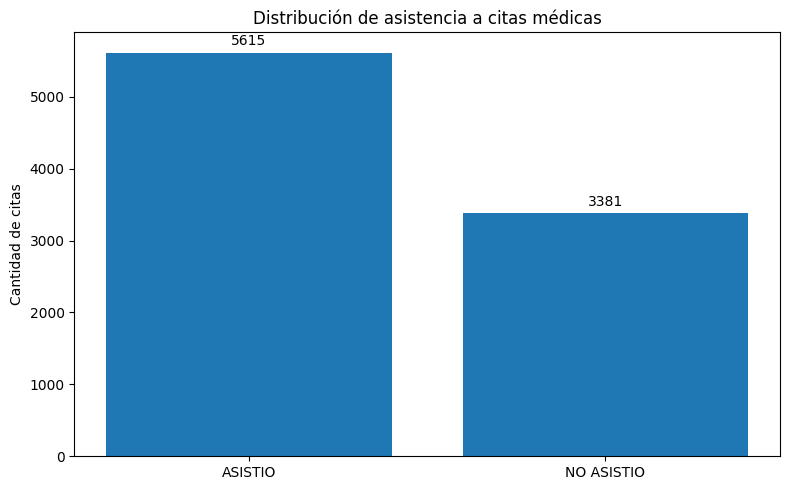

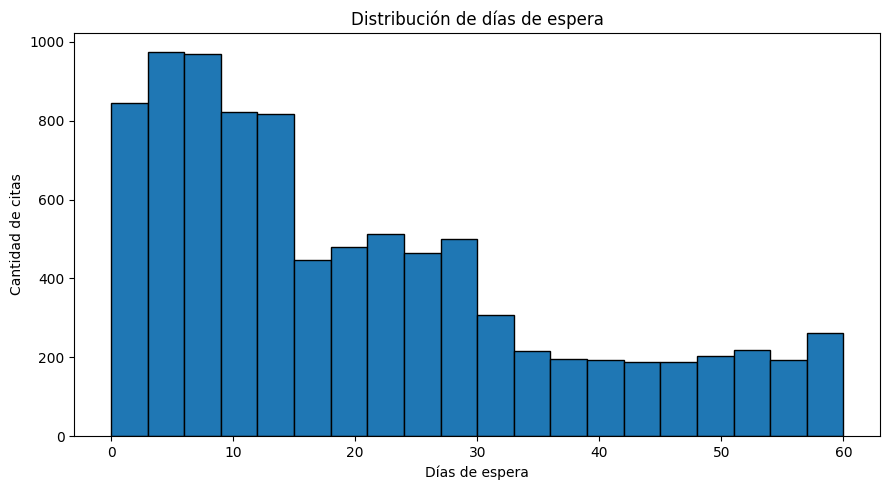

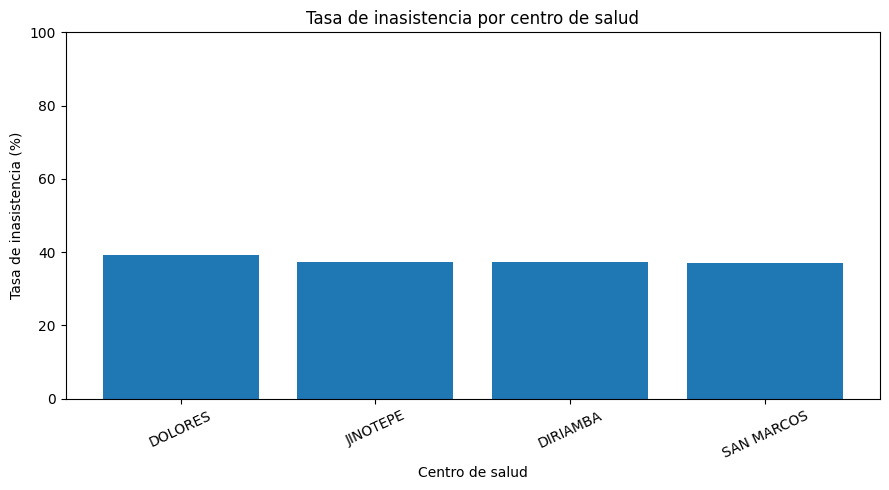

Guardado: perfil_columnas_20261025T014942Z.csv
Guardado: distribucion_asistencia_20261025T014942Z.csv
Guardado: estadisticas_numericas_20261025T014942Z.csv
Guardado: anomalias_numericas_20261025T014942Z.csv
Guardado: tasas_por_categoria_20261025T014942Z.csv
Guardado: tasas_citas_previas_20261025T014942Z.csv
Guardado: distribucion_mensual_20261025T014942Z.csv
Guardado: verificacion_temporal_20261025T014942Z.csv

PASO 3 FINALIZADO
Evidencias guardadas en: c:\Users\Usuario\Downloads\RedSaludCarazo_proyecto_base\resultados\02_eda
No se modificaron datos de SQL Server.
No se entrenaron modelos.


In [3]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 3. ANÁLISIS EXPLORATORIO DE DATOS (EDA)
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

from datetime import datetime, timezone
from IPython.display import display


# ============================================================
# 1. PREPARAR DATASET
# ============================================================

df_eda = datos_predictivos.copy()

objetivo = "no_asistio"

numericas = [
    "espera_dias",
    "citas_previas_perdidas"
]

categoricas = [
    "centro_salud",
    "especialidad",
    "canal_agendamiento",
    "grupo_edad",
    "tipo_cobertura"
]

requeridas = (
    [objetivo, "id_cita", "fecha_cita"]
    + numericas
    + categoricas
)

faltantes_columnas = (
    set(requeridas) - set(df_eda.columns)
)

if faltantes_columnas:
    raise ValueError(
        f"Faltan columnas: {sorted(faltantes_columnas)}"
    )

carpeta_eda = (
    proyecto
    / "resultados"
    / "02_eda"
)

carpeta_eda.mkdir(
    parents=True,
    exist_ok=True
)

fecha_ejecucion = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%SZ"
)


# ============================================================
# 2. VALIDAR TIPOS DE DATOS
# ============================================================

df_eda["fecha_cita"] = pd.to_datetime(
    df_eda["fecha_cita"],
    errors="coerce"
)

df_eda[objetivo] = pd.to_numeric(
    df_eda[objetivo],
    errors="coerce"
)

for campo in numericas:

    df_eda[campo] = pd.to_numeric(
        df_eda[campo],
        errors="coerce"
    )

if df_eda["fecha_cita"].isna().any():
    raise ValueError(
        "Existen fechas inválidas en el dataset."
    )

if not df_eda[objetivo].isin([0, 1]).all():
    raise ValueError(
        "La variable no_asistio contiene "
        "valores distintos de 0 y 1, o nulos."
    )

df_eda[objetivo] = df_eda[objetivo].astype(int)


# ============================================================
# 3. PERFIL DE COLUMNAS Y VALORES FALTANTES
# ============================================================

def contar_vacios(serie):

    return int(
        (
            serie.isna()
            |
            serie.astype("string")
            .str.strip()
            .eq("")
            .fillna(False)
        ).sum()
    )


perfil = pd.DataFrame([
    {
        "Campo": campo,
        "Tipo": str(df_eda[campo].dtype),
        "Registros": len(df_eda),
        "Faltantes": contar_vacios(df_eda[campo]),
        "Porcentaje_faltante": round(
            contar_vacios(df_eda[campo])
            / len(df_eda) * 100,
            2
        ),
        "Valores_distintos": int(
            df_eda[campo].nunique(dropna=True)
        )
    }
    for campo in df_eda.columns
])

perfil = perfil.sort_values(
    ["Faltantes", "Campo"],
    ascending=[False, True]
).reset_index(drop=True)


# ============================================================
# 4. ANALIZAR LA VARIABLE OBJETIVO
# ============================================================

distribucion_asistencia = (
    df_eda[objetivo]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename_axis("Valor")
    .reset_index(name="Cantidad")
)

distribucion_asistencia["Descripcion"] = (
    distribucion_asistencia["Valor"]
    .map({
        0: "ASISTIO",
        1: "NO ASISTIO"
    })
)

distribucion_asistencia["Porcentaje"] = (
    distribucion_asistencia["Cantidad"]
    / len(df_eda)
    * 100
).round(2)

tasa_inasistencia = (
    df_eda[objetivo].mean() * 100
)


# ============================================================
# 5. ESTADÍSTICAS NUMÉRICAS
# ============================================================

estadisticas_numericas = (
    df_eda[numericas]
    .describe()
    .T
    .round(2)
)

anomalias_numericas = pd.DataFrame([
    {
        "Campo": campo,
        "Nulos": int(df_eda[campo].isna().sum()),
        "Negativos": int(
            df_eda[campo].lt(0).sum()
        ),
        "No_enteros": int(
            (
                df_eda[campo].notna()
                & df_eda[campo].mod(1).ne(0)
            ).sum()
        )
    }
    for campo in numericas
])


# ============================================================
# 6. TASAS DE INASISTENCIA POR CATEGORÍA
# ============================================================

def calcular_tasa_por_categoria(datos, campo):

    temporal = datos[[campo, objetivo]].copy()

    temporal[campo] = (
        temporal[campo]
        .astype("string")
        .str.strip()
        .fillna("SIN DATO")
        .replace("", "SIN DATO")
    )

    tabla = (
        temporal
        .groupby(campo, dropna=False)
        .agg(
            Total_citas=(objetivo, "size"),
            Inasistencias=(objetivo, "sum")
        )
        .reset_index()
    )

    tabla["Asistencias"] = (
        tabla["Total_citas"]
        - tabla["Inasistencias"]
    )

    tabla["Tasa_inasistencia_pct"] = (
        tabla["Inasistencias"]
        / tabla["Total_citas"]
        * 100
    ).round(2)

    tabla["Variable"] = campo

    return tabla.sort_values(
        "Tasa_inasistencia_pct",
        ascending=False
    ).reset_index(drop=True)


tablas_categoricas = [
    calcular_tasa_por_categoria(df_eda, campo)
    for campo in categoricas
]

tasas_categoricas = pd.concat(
    tablas_categoricas,
    ignore_index=True
)


# ============================================================
# 7. TASAS SEGÚN CITAS PREVIAS PERDIDAS
# ============================================================

tasas_citas_previas = (
    df_eda
    .groupby("citas_previas_perdidas")
    .agg(
        Total_citas=(objetivo, "size"),
        Inasistencias=(objetivo, "sum")
    )
    .reset_index()
)

tasas_citas_previas["Tasa_inasistencia_pct"] = (
    tasas_citas_previas["Inasistencias"]
    / tasas_citas_previas["Total_citas"]
    * 100
).round(2)


# ============================================================
# 8. DISTRIBUCIÓN TEMPORAL
# ============================================================

df_eda["periodo_eda"] = (
    df_eda["fecha_cita"]
    .dt.to_period("M")
    .astype(str)
)

distribucion_mensual = (
    df_eda
    .groupby("periodo_eda")
    .agg(
        Total_citas=(objetivo, "size"),
        Inasistencias=(objetivo, "sum")
    )
    .reset_index()
)

distribucion_mensual["Tasa_inasistencia_pct"] = (
    distribucion_mensual["Inasistencias"]
    / distribucion_mensual["Total_citas"]
    * 100
).round(2)

# Verificar variables temporales derivadas
comparacion_temporal = []

for campo, calculado in [
    ("anio", df_eda["fecha_cita"].dt.year),
    ("mes", df_eda["fecha_cita"].dt.month)
]:

    if campo in df_eda.columns:

        almacenado = pd.to_numeric(
            df_eda[campo],
            errors="coerce"
        )

        inconsistencias = int(
            (
                almacenado.isna()
                | almacenado.ne(calculado)
            ).sum()
        )

        comparacion_temporal.append({
            "Campo": campo,
            "Registros_evaluados": len(df_eda),
            "Inconsistencias": inconsistencias
        })

verificacion_temporal = pd.DataFrame(
    comparacion_temporal
)


# ============================================================
# 9. CONTROL DE IDENTIFICADORES
# ============================================================

ids = (
    df_eda["id_cita"]
    .astype("string")
    .str.strip()
    .str.upper()
)

ids_repetidos = int(
    ids.duplicated(keep=False).sum()
)


# ============================================================
# 10. MOSTRAR RESULTADOS
# ============================================================

print("=" * 70)
print("RED SALUD INTEGRAL CARAZO")
print("PASO 3. ANÁLISIS EXPLORATORIO (EDA)")
print("=" * 70)

print("\n1. INFORMACIÓN GENERAL")
print("Registros:", len(df_eda))
print("Columnas originales del dataset:",
      len(datos_predictivos.columns))
print("IDs repetidos:", ids_repetidos)

print("\n2. PERFIL DE COLUMNAS")
display(perfil)

print("\n3. DISTRIBUCIÓN DE ASISTENCIA")
display(distribucion_asistencia)

print(
    f"\nTasa general de inasistencia: "
    f"{tasa_inasistencia:.2f}%"
)

print("\n4. ESTADÍSTICAS NUMÉRICAS")
display(estadisticas_numericas)

print("\n5. ANOMALÍAS NUMÉRICAS")
display(anomalias_numericas)

print("\n6. INASISTENCIA POR CENTRO")
display(tasas_categoricas.loc[
    tasas_categoricas["Variable"] == "centro_salud"
])

print("\n7. INASISTENCIA POR ESPECIALIDAD")
display(tasas_categoricas.loc[
    tasas_categoricas["Variable"] == "especialidad"
])

print("\n8. INASISTENCIA POR CANAL")
display(tasas_categoricas.loc[
    tasas_categoricas["Variable"] == "canal_agendamiento"
])

print("\n9. INASISTENCIA SEGÚN CITAS PREVIAS")
display(tasas_citas_previas)

print("\n10. DISTRIBUCIÓN MENSUAL")
display(distribucion_mensual)

print("\n11. VERIFICACIÓN DE ANIO Y MES")
display(verificacion_temporal)


# ============================================================
# 11. GRÁFICO DE DISTRIBUCIÓN DE ASISTENCIA
# ============================================================

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    distribucion_asistencia["Descripcion"],
    distribucion_asistencia["Cantidad"]
)

ax.bar_label(
    barras,
    padding=3,
    fmt="%.0f"
)

ax.set_title("Distribución de asistencia a citas médicas")
ax.set_ylabel("Cantidad de citas")

plt.tight_layout()

plt.savefig(
    carpeta_eda / f"distribucion_asistencia_{fecha_ejecucion}.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 12. GRÁFICO DE DÍAS DE ESPERA
# ============================================================

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    df_eda["espera_dias"].dropna(),
    bins=20,
    edgecolor="black"
)

ax.set_title("Distribución de días de espera")
ax.set_xlabel("Días de espera")
ax.set_ylabel("Cantidad de citas")

plt.tight_layout()

plt.savefig(
    carpeta_eda / f"dias_espera_{fecha_ejecucion}.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 13. GRÁFICO DE TASA DE INASISTENCIA POR CENTRO
# ============================================================

centros = tasas_categoricas.loc[
    tasas_categoricas["Variable"] == "centro_salud"
].copy()

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    centros["centro_salud"].astype(str),
    centros["Tasa_inasistencia_pct"]
)

ax.set_title("Tasa de inasistencia por centro de salud")
ax.set_xlabel("Centro de salud")
ax.set_ylabel("Tasa de inasistencia (%)")
ax.set_ylim(0, 100)

ax.tick_params(
    axis="x",
    labelrotation=25
)

plt.tight_layout()

plt.savefig(
    carpeta_eda / f"inasistencia_por_centro_{fecha_ejecucion}.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 14. GUARDAR EVIDENCIAS
# ============================================================

evidencias_eda = {
    "perfil_columnas": perfil,
    "distribucion_asistencia": distribucion_asistencia,
    "estadisticas_numericas": estadisticas_numericas,
    "anomalias_numericas": anomalias_numericas,
    "tasas_por_categoria": tasas_categoricas,
    "tasas_citas_previas": tasas_citas_previas,
    "distribucion_mensual": distribucion_mensual,
    "verificacion_temporal": verificacion_temporal
}

for nombre, tabla in evidencias_eda.items():

    ruta = (
        carpeta_eda
        / f"{nombre}_{fecha_ejecucion}.csv"
    )

    tabla.to_csv(
        ruta,
        index=True if nombre == "estadisticas_numericas"
              else False,
        encoding="utf-8-sig"
    )

    print("Guardado:", ruta.name)


print("\n" + "=" * 70)
print("PASO 3 FINALIZADO")
print("=" * 70)

print("Evidencias guardadas en:", carpeta_eda)
print("No se modificaron datos de SQL Server.")
print("No se entrenaron modelos.")



## PASO 4. Preparación y división cronológica

### Objetivo
Preparar el conjunto predictivo y dividirlo cronológicamente en entrenamiento, validación y prueba.

### Metodología
- Entrenamiento: enero a abril de 2026.
- Validación: mayo de 2026.
- Prueba final: junio de 2026.

### Control de fuga de información
La variable no_asistio se utilizará exclusivamente como objetivo.

Los identificadores no se utilizarán para entrenar.

La variable citas_previas_perdidas queda pendiente de verificar que representa únicamente antecedentes conocidos antes de cada cita.

Las transformaciones estadísticas y categóricas se ajustarán posteriormente usando solo el entrenamiento.


In [4]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 4. PREPARACIÓN Y DIVISIÓN CRONOLÓGICA
# ============================================================

import pandas as pd
from IPython.display import display


# ============================================================
# 1. PREPARAR LOS DATOS
# ============================================================

df_modelado = df_eda.copy()

df_modelado["fecha_cita"] = pd.to_datetime(
    df_modelado["fecha_cita"],
    errors="coerce"
)

if df_modelado["fecha_cita"].isna().any():
    raise ValueError("Existen fechas inválidas.")

if not df_modelado["no_asistio"].isin([0, 1]).all():
    raise ValueError("La variable objetivo contiene valores inválidos.")

if df_modelado["id_cita"].duplicated().any():
    raise ValueError("Existen identificadores repetidos.")


# ============================================================
# 2. VARIABLES PREDICTORAS
# ============================================================

# Por ahora usamos variables que pueden conocerse
# antes de la cita, sujetas a verificar su momento
# real de disponibilidad en la fuente.

numericas_modelo = [
    "espera_dias"
]

categoricas_modelo = [
    "centro_salud",
    "especialidad",
    "canal_agendamiento",
    "grupo_edad",
    "tipo_cobertura",
    "mes"
]

# Esta variable presenta una asociación muy fuerte
# con la inasistencia. No se habilitará hasta
# comprobar que contiene solo antecedentes.

usar_citas_previas = False

if usar_citas_previas:
    numericas_modelo.append(
        "citas_previas_perdidas"
    )

features = (
    numericas_modelo
    + categoricas_modelo
)

target = "no_asistio"

columnas_requeridas = (
    features
    + [target, "id_cita", "fecha_cita"]
)

faltantes = set(columnas_requeridas) - set(
    df_modelado.columns
)

if faltantes:
    raise ValueError(
        f"Columnas faltantes: {sorted(faltantes)}"
    )


# ============================================================
# 3. DIVISIÓN CRONOLÓGICA
# ============================================================

train = df_modelado.loc[
    (df_modelado["fecha_cita"] >= "2026-01-01")
    & (df_modelado["fecha_cita"] < "2026-05-01")
].copy()

val = df_modelado.loc[
    (df_modelado["fecha_cita"] >= "2026-05-01")
    & (df_modelado["fecha_cita"] < "2026-06-01")
].copy()

test = df_modelado.loc[
    (df_modelado["fecha_cita"] >= "2026-06-01")
    & (df_modelado["fecha_cita"] < "2026-07-01")
].copy()


# ============================================================
# 4. VERIFICAR LOS CONJUNTOS
# ============================================================

conjuntos = {
    "ENTRENAMIENTO": train,
    "VALIDACION": val,
    "PRUEBA": test
}

for nombre, datos in conjuntos.items():

    if datos.empty:
        raise ValueError(
            f"El conjunto {nombre} está vacío."
        )

    if datos[target].nunique() != 2:
        raise ValueError(
            f"{nombre} no contiene ambas clases."
        )

assert (
    len(train) + len(val) + len(test)
    == len(df_modelado)
), "Hay registros fuera del período definido."

ids_train = set(train["id_cita"])
ids_val = set(val["id_cita"])
ids_test = set(test["id_cita"])

assert not (
    ids_train & ids_val
    or ids_train & ids_test
    or ids_val & ids_test
), "Hay citas compartidas entre conjuntos."

assert train["fecha_cita"].max() < val["fecha_cita"].min()
assert val["fecha_cita"].max() < test["fecha_cita"].min()


# ============================================================
# 5. SEPARAR X E Y
# ============================================================

X_train = train[features].copy()
y_train = train[target].astype(int)

X_val = val[features].copy()
y_val = val[target].astype(int)

X_test = test[features].copy()
y_test = test[target].astype(int)

assert target not in X_train.columns
assert "id_cita" not in X_train.columns


# ============================================================
# 6. CREAR RESUMEN DE DISTRIBUCIÓN
# ============================================================

resumen_division = []

for nombre, datos in conjuntos.items():

    cantidad = len(datos)
    inasistencias = int(datos[target].sum())

    resumen_division.append({
        "Conjunto": nombre,
        "Registros": cantidad,
        "Asistencias": cantidad - inasistencias,
        "Inasistencias": inasistencias,
        "Tasa_inasistencia_pct": round(
            inasistencias / cantidad * 100,
            2
        ),
        "Fecha_minima": datos["fecha_cita"].min().date(),
        "Fecha_maxima": datos["fecha_cita"].max().date()
    })

tabla_division = pd.DataFrame(
    resumen_division
)


# ============================================================
# 7. MOSTRAR RESULTADOS
# ============================================================

print("=" * 70)
print("MINERÍA DE DATOS - RED SALUD INTEGRAL CARAZO")
print("PASO 4. DIVISIÓN CRONOLÓGICA")
print("=" * 70)

print("\n1. VARIABLES UTILIZADAS")
display(pd.DataFrame({
    "Variable": features,
    "Tipo": [
        "NUMERICA"
        if campo in numericas_modelo
        else "CATEGORICA"
        for campo in features
    ]
}))

print("\n2. CONJUNTOS GENERADOS")
display(tabla_division)

print("\n3. DIMENSIONES")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\n4. CONTROL DE INFORMACIÓN")
print("Variable objetivo:", target)
print("Citas previas habilitadas:", usar_citas_previas)
print("Identificadores separados: SI")
print("Conjuntos sin citas compartidas: SI")
print("División temporal: VERIFICADA")


# ============================================================
# 8. GUARDAR EVIDENCIA
# ============================================================

carpeta_preparacion = (
    proyecto
    / "resultados"
    / "03_preparacion"
)

carpeta_preparacion.mkdir(
    parents=True,
    exist_ok=True
)

tabla_division.to_csv(
    carpeta_preparacion / "division_cronologica.csv",
    index=False,
    encoding="utf-8-sig"
)

pd.DataFrame({
    "Variable": features
}).to_csv(
    carpeta_preparacion / "variables_seleccionadas.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nPASO 4 FINALIZADO")
print("No se entrenaron modelos.")
print("No se modificaron datos en SQL Server.")


MINERÍA DE DATOS - RED SALUD INTEGRAL CARAZO
PASO 4. DIVISIÓN CRONOLÓGICA

1. VARIABLES UTILIZADAS


,Variable,Tipo
0,espera_dias,NUMERICA
1,centro_salud,CATEGORICA
2,especialidad,CATEGORICA
3,canal_agendamiento,CATEGORICA
4,grupo_edad,CATEGORICA
5,tipo_cobertura,CATEGORICA
6,mes,CATEGORICA



2. CONJUNTOS GENERADOS


,Conjunto,Registros,Asistencias,Inasistencias,Tasa_inasistencia_pct,Fecha_minima,Fecha_maxima
0,ENTRENAMIENTO,5948,3690,2258,37.96,2026-01-01,2026-04-30
1,VALIDACION,1511,951,560,37.06,2026-05-01,2026-05-31
2,PRUEBA,1537,974,563,36.63,2026-06-01,2026-06-30



3. DIMENSIONES
X_train: (5948, 7)
X_val: (1511, 7)
X_test: (1537, 7)

4. CONTROL DE INFORMACIÓN
Variable objetivo: no_asistio
Citas previas habilitadas: False
Identificadores separados: SI
Conjuntos sin citas compartidas: SI
División temporal: VERIFICADA

PASO 4 FINALIZADO
No se entrenaron modelos.
No se modificaron datos en SQL Server.



## PASO 5. Entrenamiento inicial de tres modelos predictivos

### Objetivo
Entrenar tres algoritmos de clasificación para predecir la inasistencia a citas médicas y evaluar su rendimiento en el conjunto de validación.

### Modelos
- M1: Regresión Logística.
- M2: Random Forest.
- M3: Gradient Boosting.

### KPI principales
- Recall: capacidad para detectar inasistencias reales.
- Precision: proporción de alertas de inasistencia correctas.
- F2-Score: equilibrio que da mayor importancia al Recall.

### Metodología
El preprocesamiento se realiza mediante Pipeline de scikit-learn.

Las transformaciones se ajustan solamente con los registros de entrenamiento (enero–abril de 2026).

Los modelos se evalúan inicialmente con mayo de 2026.

El conjunto de prueba de junio de 2026 permanece reservado para la evaluación final.

### Alcance
Se entrenan tres modelos candidatos. La asignación definitiva de un modelo a cada KPI se realizará según los resultados de validación.


In [5]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 5. ENTRENAMIENTO DE TRES MODELOS
# ============================================================

import sys
import json
import joblib
import numpy as np
import pandas as pd
import sklearn

from datetime import datetime, timezone
from IPython.display import display

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)


# ============================================================
# 1. VERIFICAR LOS DATOS DEL PASO 4
# ============================================================

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)

assert len(X_train) == 5948
assert len(X_val) == 1511

assert list(X_train.columns) == list(X_val.columns)

assert "no_asistio" not in X_train.columns
assert "id_cita" not in X_train.columns

print("=" * 70)
print("RED SALUD INTEGRAL CARAZO")
print("PASO 5. ENTRENAMIENTO DE MODELOS")
print("=" * 70)

print("\nDATOS")
print("Entrenamiento:", len(X_train))
print("Validación:", len(X_val))
print("Variables:", X_train.shape[1])

print("\nVersión de scikit-learn:", sklearn.__version__)


# ============================================================
# 2. PREPARAR VARIABLES
# ============================================================

# Se respetan las variables definidas
# en el PASO 4.

X_entrenamiento = X_train.copy()
X_validacion = X_val.copy()

for campo in numericas_modelo:

    X_entrenamiento[campo] = pd.to_numeric(
        X_entrenamiento[campo],
        errors="coerce"
    )

    X_validacion[campo] = pd.to_numeric(
        X_validacion[campo],
        errors="coerce"
    )

for campo in categoricas_modelo:

    X_entrenamiento[campo] = (
        X_entrenamiento[campo]
        .astype("object")
    )

    X_validacion[campo] = (
        X_validacion[campo]
        .astype("object")
    )


# ============================================================
# 3. CREAR EL PREPROCESAMIENTO
# ============================================================

def crear_preprocesador():

    # Compatibilidad con distintas versiones
    # de scikit-learn.

    try:
        codificador = OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )

    except TypeError:
        codificador = OneHotEncoder(
            handle_unknown="ignore",
            sparse=False
        )

    pipeline_numerico = Pipeline([
        (
            "imputador",
            SimpleImputer(strategy="median")
        ),
        (
            "escalador",
            StandardScaler()
        )
    ])

    pipeline_categorico = Pipeline([
        (
            "imputador",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "codificador",
            codificador
        )
    ])

    return ColumnTransformer(
        transformers=[
            (
                "numericas",
                pipeline_numerico,
                numericas_modelo
            ),
            (
                "categoricas",
                pipeline_categorico,
                categoricas_modelo
            )
        ],
        remainder="drop"
    )


# ============================================================
# 4. DEFINIR LOS TRES MODELOS
# ============================================================

algoritmos = {

    "M1_REGRESION_LOGISTICA": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "M2_RANDOM_FOREST": RandomForestClassifier(
        n_estimators=250,
        max_depth=10,
        min_samples_leaf=3,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ),

    "M3_GRADIENT_BOOSTING": GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}


# ============================================================
# 5. PROGRAMAR LOS KPI PREDICTIVOS
# ============================================================

def evaluar_kpi_modelo(
    valores_reales,
    predicciones,
    probabilidades
):

    # Métricas expresadas entre 0 y 1.
    # En la tabla se muestran como porcentaje.

    return {

        "Accuracy": accuracy_score(
            valores_reales,
            predicciones
        ),

        "Precision": precision_score(
            valores_reales,
            predicciones,
            zero_division=0
        ),

        "Recall": recall_score(
            valores_reales,
            predicciones,
            zero_division=0
        ),

        "F1_Score": f1_score(
            valores_reales,
            predicciones,
            zero_division=0
        ),

        "F2_Score": fbeta_score(
            valores_reales,
            predicciones,
            beta=2,
            zero_division=0
        ),

        "ROC_AUC": roc_auc_score(
            valores_reales,
            probabilidades
        ),

        "Average_Precision": average_precision_score(
            valores_reales,
            probabilidades
        )
    }


# ============================================================
# 6. CREAR CARPETAS DE EVIDENCIAS
# ============================================================

carpeta_modelos = (
    proyecto
    / "resultados"
    / "04_modelos"
)

carpeta_kpi = (
    proyecto
    / "resultados"
    / "05_kpi"
)

carpeta_modelos.mkdir(
    parents=True,
    exist_ok=True
)

carpeta_kpi.mkdir(
    parents=True,
    exist_ok=True
)

fecha_modelado = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%SZ")


# ============================================================
# 7. ENTRENAR Y VALIDAR LOS MODELOS
# ============================================================

modelos_entrenados = {}
resultados_validacion = []
predicciones_validacion = []

for nombre, algoritmo in algoritmos.items():

    print("\n" + "-" * 70)
    print("ENTRENANDO:", nombre)
    print("-" * 70)

    # Cada modelo tiene su propio Pipeline.
    # Las transformaciones se aprenden
    # solamente durante fit(X_entrenamiento).

    pipeline_modelo = Pipeline([
        (
            "preprocesamiento",
            crear_preprocesador()
        ),
        (
            "clasificador",
            algoritmo
        )
    ])

    # Entrenamiento
    pipeline_modelo.fit(
        X_entrenamiento,
        y_train
    )

    # Evaluación sobre mayo
    predicciones = pipeline_modelo.predict(
        X_validacion
    )

    probabilidades = (
        pipeline_modelo.predict_proba(
            X_validacion
        )[:, 1]
    )

    # Calcular los KPI
    metricas = evaluar_kpi_modelo(
        y_val,
        predicciones,
        probabilidades
    )

    # Obtener matriz de confusión
    vn, fp, fn, vp = confusion_matrix(
        y_val,
        predicciones,
        labels=[0, 1]
    ).ravel()

    # Guardar modelo en memoria
    modelos_entrenados[nombre] = pipeline_modelo

    # Tabla comparativa
    resultados_validacion.append({
        "Modelo": nombre,
        "Entrenamiento": len(X_entrenamiento),
        "Validacion": len(X_validacion),
        "Umbral": 0.50,
        "Accuracy": round(metricas["Accuracy"] * 100, 2),
        "Precision": round(metricas["Precision"] * 100, 2),
        "Recall": round(metricas["Recall"] * 100, 2),
        "F1_Score": round(metricas["F1_Score"] * 100, 2),
        "F2_Score": round(metricas["F2_Score"] * 100, 2),
        "ROC_AUC": round(metricas["ROC_AUC"], 4),
        "Average_Precision": round(
            metricas["Average_Precision"], 4
        ),
        "VP": int(vp),
        "VN": int(vn),
        "FP": int(fp),
        "FN": int(fn)
    })

    # Evidencia individual de predicciones
    tabla_predicciones = pd.DataFrame({
        "id_cita": val["id_cita"].to_numpy(),
        "fecha_cita": val["fecha_cita"].to_numpy(),
        "Valor_real": y_val.to_numpy(),
        "Prediccion": predicciones,
        "Probabilidad_inasistencia": probabilidades,
        "Modelo": nombre
    })

    predicciones_validacion.append(
        tabla_predicciones
    )

    # Guardar modelo entrenado
    ruta_modelo = (
        carpeta_modelos
        / f"{nombre}_{fecha_modelado}.joblib"
    )

    joblib.dump(
        pipeline_modelo,
        ruta_modelo
    )

    print("Modelo entrenado y evaluado.")
    print("Guardado:", ruta_modelo.name)


# ============================================================
# 8. CONSTRUIR TABLAS FINALES
# ============================================================

comparacion_modelos = pd.DataFrame(
    resultados_validacion
)

detalle_predicciones = pd.concat(
    predicciones_validacion,
    ignore_index=True
)

columnas_principales = [
    "Modelo",
    "Accuracy",
    "Precision",
    "Recall",
    "F1_Score",
    "F2_Score",
    "ROC_AUC",
    "Average_Precision"
]


# ============================================================
# 9. MOSTRAR COMPARACIÓN
# ============================================================

print("\n" + "=" * 70)
print("RESULTADOS DE VALIDACIÓN - MAYO 2026")
print("=" * 70)

display(
    comparacion_modelos[columnas_principales]
)

print("\nMATRICES DE CONFUSIÓN")
display(
    comparacion_modelos[
        ["Modelo", "VP", "VN", "FP", "FN"]
    ]
)


# ============================================================
# 10. COMPARAR LOS TRES KPI PRINCIPALES
# ============================================================

kpi_principales = [
    {
        "Codigo": "KPI-M01",
        "KPI": "Recall",
        "Interpretacion": (
            "Proporción de inasistencias "
            "reales detectadas"
        )
    },
    {
        "Codigo": "KPI-M02",
        "KPI": "Precision",
        "Interpretacion": (
            "Proporción de alertas "
            "de inasistencia correctas"
        )
    },
    {
        "Codigo": "KPI-M03",
        "KPI": "F2_Score",
        "Interpretacion": (
            "Equilibrio con mayor "
            "peso del Recall"
        )
    }
]

tabla_kpi_mineria = pd.DataFrame(
    kpi_principales
)

print("\nTRES KPI PROGRAMADOS")
display(tabla_kpi_mineria)

print("\nMEJOR RESULTADO INICIAL POR KPI")

for indicador in [
    "Recall",
    "Precision",
    "F2_Score"
]:

    mejor = comparacion_modelos.loc[
        comparacion_modelos[indicador].idxmax()
    ]

    print(
        indicador,
        "->",
        mejor["Modelo"],
        "|",
        f"{mejor[indicador]:.2f}%"
    )

print(
    "\nIMPORTANTE: todavía no se han asignado "
    "los tres modelos definitivos."
)


# ============================================================
# 11. VERIFICACIONES
# ============================================================

assert len(modelos_entrenados) == 3

assert len(comparacion_modelos) == 3

assert (
    detalle_predicciones["Modelo"].nunique() == 3
)

assert all(
    len(datos) == len(X_val)
    for datos in predicciones_validacion
)

print("\nMODELOS ENTRENADOS: 3/3")
print("CONJUNTO EVALUADO: VALIDACIÓN (MAYO)")
print("CONJUNTO DE PRUEBA (JUNIO): NO UTILIZADO")


# ============================================================
# 12. GUARDAR RESULTADOS
# ============================================================

ruta_comparacion = (
    carpeta_modelos
    / f"comparacion_validacion_{fecha_modelado}.csv"
)

ruta_predicciones = (
    carpeta_modelos
    / f"predicciones_validacion_{fecha_modelado}.csv"
)

ruta_kpi = (
    carpeta_kpi
    / f"kpi_programados_{fecha_modelado}.csv"
)

comparacion_modelos.to_csv(
    ruta_comparacion,
    index=False,
    encoding="utf-8-sig"
)

detalle_predicciones.to_csv(
    ruta_predicciones,
    index=False,
    encoding="utf-8-sig"
)

tabla_kpi_mineria.to_csv(
    ruta_kpi,
    index=False,
    encoding="utf-8-sig"
)

print("\nEVIDENCIAS GUARDADAS")
print(ruta_comparacion.name)
print(ruta_predicciones.name)
print(ruta_kpi.name)

print("\nPASO 5 FINALIZADO")
print("No se modificó SQL Server.")


RED SALUD INTEGRAL CARAZO
PASO 5. ENTRENAMIENTO DE MODELOS

DATOS
Entrenamiento: 5948
Validación: 1511
Variables: 7

Versión de scikit-learn: 1.9.1

----------------------------------------------------------------------
ENTRENANDO: M1_REGRESION_LOGISTICA
----------------------------------------------------------------------
Modelo entrenado y evaluado.
Guardado: M1_REGRESION_LOGISTICA_20261025T015659Z.joblib

----------------------------------------------------------------------
ENTRENANDO: M2_RANDOM_FOREST
----------------------------------------------------------------------
Modelo entrenado y evaluado.
Guardado: M2_RANDOM_FOREST_20261025T015659Z.joblib

----------------------------------------------------------------------
ENTRENANDO: M3_GRADIENT_BOOSTING
----------------------------------------------------------------------
Modelo entrenado y evaluado.
Guardado: M3_GRADIENT_BOOSTING_20261025T015659Z.joblib

RESULTADOS DE VALIDACIÓN - MAYO 2026


,Modelo,Accuracy,Precision,Recall,F1_Score,F2_Score,ROC_AUC,Average_Precision
0,M1_REGRESION_LOGISTICA,59.03,45.32,51.07,48.03,49.81,0.6097,0.4617
1,M2_RANDOM_FOREST,60.95,47.74,56.61,51.80,54.58,0.6148,0.4526
2,M3_GRADIENT_BOOSTING,61.42,46.23,25.18,32.60,27.70,0.6192,0.4487



MATRICES DE CONFUSIÓN


,Modelo,VP,VN,FP,FN
0,M1_REGRESION_LOGISTICA,286,606,345,274
1,M2_RANDOM_FOREST,317,604,347,243
2,M3_GRADIENT_BOOSTING,141,787,164,419



TRES KPI PROGRAMADOS


,Codigo,KPI,Interpretacion
0,KPI-M01,Recall,Proporción de inasistencias reales detectadas
1,KPI-M02,Precision,Proporción de alertas de inasistencia correctas
2,KPI-M03,F2_Score,Equilibrio con mayor peso del Recall



MEJOR RESULTADO INICIAL POR KPI
Recall -> M2_RANDOM_FOREST | 56.61%
Precision -> M2_RANDOM_FOREST | 47.74%
F2_Score -> M2_RANDOM_FOREST | 54.58%

IMPORTANTE: todavía no se han asignado los tres modelos definitivos.

MODELOS ENTRENADOS: 3/3
CONJUNTO EVALUADO: VALIDACIÓN (MAYO)
CONJUNTO DE PRUEBA (JUNIO): NO UTILIZADO

EVIDENCIAS GUARDADAS
comparacion_validacion_20261025T015659Z.csv
predicciones_validacion_20261025T015659Z.csv
kpi_programados_20261025T015659Z.csv

PASO 5 FINALIZADO
No se modificó SQL Server.



## PASO 6. Comparación ampliada y selección por KPI

### Objetivo
Comparar algoritmos de clasificación sobre el conjunto de validación y seleccionar tres modelos distintos, asociados a Recall, Precision y F2-Score.

### Metodología
- Mantener las siete variables seleccionadas.
- Utilizar el entrenamiento de enero a abril.
- Comparar resultados con mayo.
- Mantener el umbral de clasificación en 0.50.
- Seleccionar tres modelos diferentes considerando su rendimiento en los KPI.

### Consideraciones
La selección se realiza exclusivamente mediante validación. Los datos de junio se reservan para la evaluación final.

La asignación de tres modelos diferentes puede requerir aceptar un resultado inferior al máximo individual de algún KPI. Esta diferencia debe documentarse.


In [6]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 6. COMPARACIÓN AMPLIADA Y SELECCIÓN POR KPI
# ============================================================

import joblib
import pandas as pd

from itertools import permutations
from datetime import datetime, timezone
from IPython.display import display

from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB


# ============================================================
# 1. COMPROBAR LOS TRES MODELOS ANTERIORES
# ============================================================

if len(modelos_entrenados) != 3:
    raise ValueError(
        "Primero debes ejecutar el PASO 5."
    )

comparacion_ampliada = comparacion_modelos.copy()

fecha_ampliacion = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%SZ")


# ============================================================
# 2. DEFINIR CINCO ALGORITMOS ADICIONALES
# ============================================================

algoritmos_adicionales = {

    "M4_ARBOL_DECISION": DecisionTreeClassifier(
        max_depth=6,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=42
    ),

    "M5_EXTRA_TREES": ExtraTreesClassifier(
        n_estimators=250,
        max_depth=12,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "M6_HIST_GRADIENT_BOOSTING":
        HistGradientBoostingClassifier(
            max_iter=180,
            learning_rate=0.05,
            max_leaf_nodes=15,
            random_state=42
        ),

    "M7_KNN": KNeighborsClassifier(
        n_neighbors=21,
        weights="distance"
    ),

    "M8_NAIVE_BAYES": GaussianNB()
}


# ============================================================
# 3. ENTRENAR Y EVALUAR NUEVOS CANDIDATOS
# ============================================================

resultados_adicionales = []

for nombre, algoritmo in algoritmos_adicionales.items():

    print("\nENTRENANDO:", nombre)

    pipeline = Pipeline([
        (
            "preprocesamiento",
            crear_preprocesador()
        ),
        (
            "clasificador",
            algoritmo
        )
    ])

    pipeline.fit(
        X_entrenamiento,
        y_train
    )

    probabilidades = pipeline.predict_proba(
        X_validacion
    )[:, 1]

    predicciones = (
        probabilidades >= 0.50
    ).astype(int)

    metricas = evaluar_kpi_modelo(
        y_val,
        predicciones,
        probabilidades
    )

    resultados_adicionales.append({
        "Modelo": nombre,
        "Entrenamiento": len(X_entrenamiento),
        "Validacion": len(X_validacion),
        "Umbral": 0.50,
        "Accuracy": round(
            metricas["Accuracy"] * 100, 2
        ),
        "Precision": round(
            metricas["Precision"] * 100, 2
        ),
        "Recall": round(
            metricas["Recall"] * 100, 2
        ),
        "F1_Score": round(
            metricas["F1_Score"] * 100, 2
        ),
        "F2_Score": round(
            metricas["F2_Score"] * 100, 2
        ),
        "ROC_AUC": round(
            metricas["ROC_AUC"], 4
        ),
        "Average_Precision": round(
            metricas["Average_Precision"], 4
        )
    })

    modelos_entrenados[nombre] = pipeline

    ruta = (
        carpeta_modelos
        / f"{nombre}_{fecha_ampliacion}.joblib"
    )

    joblib.dump(pipeline, ruta)

    print("Modelo guardado:", ruta.name)


# ============================================================
# 4. CONSOLIDAR LOS OCHO MODELOS
# ============================================================

nuevos = pd.DataFrame(
    resultados_adicionales
)

comparacion_ampliada = pd.concat(
    [comparacion_ampliada, nuevos],
    ignore_index=True
)

columnas_comparacion = [
    "Modelo",
    "Accuracy",
    "Precision",
    "Recall",
    "F1_Score",
    "F2_Score",
    "ROC_AUC",
    "Average_Precision"
]

print("\n" + "=" * 70)
print("COMPARACIÓN DE OCHO ALGORITMOS")
print("=" * 70)

display(
    comparacion_ampliada[
        columnas_comparacion
    ].sort_values(
        "F2_Score",
        ascending=False
    ).reset_index(drop=True)
)


# ============================================================
# 5. OBTENER EL MEJOR MODELO INDIVIDUAL POR KPI
# ============================================================

indicadores = [
    "Recall",
    "Precision",
    "F2_Score"
]

mejores_individuales = []

for indicador in indicadores:

    ganador = comparacion_ampliada.loc[
        comparacion_ampliada[indicador].idxmax()
    ]

    mejores_individuales.append({
        "KPI": indicador,
        "Mejor_modelo_individual": ganador["Modelo"],
        "Mejor_valor": ganador[indicador]
    })

tabla_mejores = pd.DataFrame(
    mejores_individuales
)

print("\nMEJOR MODELO INDIVIDUAL POR KPI")
display(tabla_mejores)


# ============================================================
# 6. SELECCIONAR TRES MODELOS DIFERENTES
# ============================================================

# Buscamos tres modelos distintos que maximicen
# conjuntamente sus resultados de validación.
#
# Importante:
# No garantizamos que cada uno sea el mejor
# individual de su KPI.

resultados_por_modelo = (
    comparacion_ampliada
    .set_index("Modelo")
)

nombres_modelos = (
    comparacion_ampliada["Modelo"].tolist()
)

mejor_asignacion = None
mejor_puntuacion = float("-inf")

for candidatos in permutations(
    nombres_modelos,
    3
):

    puntuacion = sum(
        resultados_por_modelo.loc[
            candidatos[i],
            indicadores[i]
        ]
        for i in range(3)
    )

    if puntuacion > mejor_puntuacion:

        mejor_puntuacion = puntuacion
        mejor_asignacion = candidatos


# ============================================================
# 7. CONSTRUIR TABLA DE ASIGNACIÓN
# ============================================================

filas_seleccion = []

for indice, indicador in enumerate(
    indicadores
):

    modelo_elegido = mejor_asignacion[indice]

    resultado_elegido = (
        resultados_por_modelo.loc[
            modelo_elegido,
            indicador
        ]
    )

    mejor_posible = (
        comparacion_ampliada[indicador].max()
    )

    filas_seleccion.append({
        "KPI": indicador,
        "Modelo_asignado": modelo_elegido,
        "Resultado_validacion_pct": resultado_elegido,
        "Mejor_individual_pct": mejor_posible,
        "Diferencia_pp": round(
            mejor_posible - resultado_elegido,
            2
        )
    })

seleccion_tres_modelos = pd.DataFrame(
    filas_seleccion
)

print("\n" + "=" * 70)
print("PROPUESTA DE TRES MODELOS DISTINTOS")
print("=" * 70)

display(seleccion_tres_modelos)


# ============================================================
# 8. COMPROBAR LA SELECCIÓN
# ============================================================

assert len(comparacion_ampliada) == 8

assert len(seleccion_tres_modelos) == 3

assert (
    seleccion_tres_modelos[
        "Modelo_asignado"
    ].nunique() == 3
)

assert set(
    seleccion_tres_modelos["KPI"]
) == {
    "Recall",
    "Precision",
    "F2_Score"
}

print("\nALGORITMOS COMPARADOS: 8")
print("MODELOS DIFERENTES ASIGNADOS: 3")
print("DATOS DE JUNIO UTILIZADOS: NO")


# ============================================================
# 9. GUARDAR EVIDENCIAS
# ============================================================

carpeta_kpi.mkdir(
    parents=True,
    exist_ok=True
)

comparacion_ampliada.to_csv(
    carpeta_modelos
    / f"comparacion_8_modelos_{fecha_ampliacion}.csv",
    index=False,
    encoding="utf-8-sig"
)

tabla_mejores.to_csv(
    carpeta_kpi
    / f"mejor_individual_kpi_{fecha_ampliacion}.csv",
    index=False,
    encoding="utf-8-sig"
)

seleccion_tres_modelos.to_csv(
    carpeta_kpi
    / f"seleccion_tres_modelos_{fecha_ampliacion}.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nPASO 6 FINALIZADO")
print("Evidencias guardadas correctamente.")
print("No se modificó SQL Server.")



ENTRENANDO: M4_ARBOL_DECISION
Modelo guardado: M4_ARBOL_DECISION_20261025T020001Z.joblib

ENTRENANDO: M5_EXTRA_TREES
Modelo guardado: M5_EXTRA_TREES_20261025T020001Z.joblib

ENTRENANDO: M6_HIST_GRADIENT_BOOSTING
Modelo guardado: M6_HIST_GRADIENT_BOOSTING_20261025T020001Z.joblib

ENTRENANDO: M7_KNN
Modelo guardado: M7_KNN_20261025T020001Z.joblib

ENTRENANDO: M8_NAIVE_BAYES
Modelo guardado: M8_NAIVE_BAYES_20261025T020001Z.joblib

COMPARACIÓN DE OCHO ALGORITMOS


,Modelo,Accuracy,Precision,Recall,F1_Score,F2_Score,ROC_AUC,Average_Precision
0,M4_ARBOL_DECISION,60.82,47.73,60.00,53.16,57.07,0.6148,0.4424
1,M2_RANDOM_FOREST,60.95,47.74,56.61,51.80,54.58,0.6148,0.4526
2,M1_REGRESION_LOGISTICA,59.03,45.32,51.07,48.03,49.81,0.6097,0.4617
3,M5_EXTRA_TREES,56.65,42.54,48.39,45.28,47.10,0.5731,0.4217
4,M6_HIST_GRADIENT_BOOSTING,60.95,45.79,29.11,35.59,31.39,0.6171,0.4538
5,M3_GRADIENT_BOOSTING,61.42,46.23,25.18,32.60,27.70,0.6192,0.4487
6,M8_NAIVE_BAYES,61.35,46.05,25.00,32.41,27.52,0.5708,0.4363
7,M7_KNN,60.49,43.85,23.57,30.66,25.97,0.5502,0.4062



MEJOR MODELO INDIVIDUAL POR KPI


,KPI,Mejor_modelo_individual,Mejor_valor
0,Recall,M4_ARBOL_DECISION,60.00
1,Precision,M2_RANDOM_FOREST,47.74
2,F2_Score,M4_ARBOL_DECISION,57.07



PROPUESTA DE TRES MODELOS DISTINTOS


,KPI,Modelo_asignado,Resultado_validacion_pct,Mejor_individual_pct,Diferencia_pp
0,Recall,M4_ARBOL_DECISION,60.00,60.00,0.00
1,Precision,M3_GRADIENT_BOOSTING,46.23,47.74,1.51
2,F2_Score,M2_RANDOM_FOREST,54.58,57.07,2.49



ALGORITMOS COMPARADOS: 8
MODELOS DIFERENTES ASIGNADOS: 3
DATOS DE JUNIO UTILIZADOS: NO

PASO 6 FINALIZADO
Evidencias guardadas correctamente.
No se modificó SQL Server.



## PASO 7. Evaluación de referencia y revisión de variables

### Objetivo
Determinar si los modelos entrenados superan métodos básicos de clasificación e investigar la procedencia de las variables que podrían mejorar su rendimiento.

### Controles
- Comparar los modelos con la predicción de asistencia constante.
- Comparar los modelos con la predicción de inasistencia constante.
- Verificar Accuracy, Precision, Recall y F2-Score.
- Investigar las reglas que construyeron el dataset predictivo.
- Revisar la disponibilidad temporal de citas_previas_perdidas.

### Criterio
No se incluirán variables que utilicen información posterior al momento de predicción.

Los datos de junio permanecen reservados para la evaluación final.


In [7]:

# ============================================================
# RED SALUD INTEGRAL CARAZO
# MINERÍA DE DATOS
# PASO 7. DIAGNÓSTICO DE MODELOS Y VARIABLES
# ============================================================

import numpy as np
import pandas as pd
import re

from pathlib import Path
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    fbeta_score
)


# ============================================================
# 1. CALCULAR DOS MODELOS DE REFERENCIA
# ============================================================

# Baseline A: predecir que todos asistirán.
pred_siempre_asiste = np.zeros(
    len(y_val),
    dtype=int
)

# Baseline B: predecir que nadie asistirá.
pred_siempre_falta = np.ones(
    len(y_val),
    dtype=int
)


def evaluar_referencia(nombre, predicciones):

    return {
        "Modelo": nombre,
        "Accuracy": round(
            accuracy_score(y_val, predicciones) * 100, 2
        ),
        "Precision": round(
            precision_score(
                y_val, predicciones, zero_division=0
            ) * 100, 2
        ),
        "Recall": round(
            recall_score(
                y_val, predicciones, zero_division=0
            ) * 100, 2
        ),
        "F2_Score": round(
            fbeta_score(
                y_val, predicciones,
                beta=2,
                zero_division=0
            ) * 100, 2
        )
    }


tabla_referencias = pd.DataFrame([
    evaluar_referencia(
        "REFERENCIA_SIEMPRE_ASISTE",
        pred_siempre_asiste
    ),
    evaluar_referencia(
        "REFERENCIA_SIEMPRE_FALTA",
        pred_siempre_falta
    )
])


# ============================================================
# 2. COMPARACIÓN CON LOS OCHO MODELOS
# ============================================================

columnas = [
    "Modelo",
    "Accuracy",
    "Precision",
    "Recall",
    "F2_Score"
]

comparacion_referencias = pd.concat(
    [
        comparacion_ampliada[columnas],
        tabla_referencias[columnas]
    ],
    ignore_index=True
)

print("=" * 65)
print("PASO 7. DIAGNÓSTICO DE MODELOS")
print("=" * 65)

print("\n1. MODELOS DE REFERENCIA")
display(tabla_referencias)

print("\n2. COMPARACIÓN GENERAL")
display(
    comparacion_referencias.sort_values(
        "F2_Score",
        ascending=False
    ).reset_index(drop=True)
)


# ============================================================
# 3. INVESTIGAR EL SCRIPT DE TRANSFORMACIÓN
# ============================================================

print("\n3. REVISIÓN DE PROCEDENCIA DE VARIABLES")

raiz_anterior = proyecto_anterior

candidatos_sql = sorted(
    raiz_anterior.rglob("02_calidad.sql")
)

if not candidatos_sql:

    print(
        "No se encontró 02_calidad.sql. "
        "Será necesario localizarlo en el proyecto anterior."
    )

else:

    archivo_sql = candidatos_sql[0]

    print("Archivo:", archivo_sql)

    contenido = archivo_sql.read_text(
        encoding="utf-8-sig",
        errors="replace"
    )

    lineas = contenido.splitlines()

    expresion = re.compile(
        r"citas_previas_perdidas"
        r"|dm_dataset_prediccion"
        r"|ROW_NUMBER"
        r"|HAVING"
        r"|PARTITION\s+BY",
        flags=re.IGNORECASE
    )

    coincidencias = [
        i for i, linea in enumerate(lineas)
        if expresion.search(linea)
    ]

    print(
        "Líneas relevantes encontradas:",
        len(coincidencias)
    )

    for indice in coincidencias[:15]:

        inicio = max(0, indice - 4)
        fin = min(len(lineas), indice + 5)

        print("\n" + "-" * 55)

        for j in range(inicio, fin):
            print(f"{j + 1:04d}: {lineas[j]}")

    if not coincidencias:
        print(
            "El script no contiene las expresiones buscadas."
        )

    print(
        "\nNOTA: identificar una columna en SQL "
        "no demuestra por sí solo que sea temporalmente segura."
    )


# ============================================================
# 4. REGISTRAR LAS VARIABLES PENDIENTES
# ============================================================

revision_variables = pd.DataFrame([
    {
        "Variable": "citas_previas_perdidas",
        "Pregunta": (
            "¿Se calcula solamente con citas "
            "anteriores a la fecha de predicción?"
        ),
        "Estado": "PENDIENTE DE VERIFICAR"
    },
    {
        "Variable": "recordatorios_enviados",
        "Pregunta": (
            "¿La cantidad se conoce en el momento "
            "en que se pretende predecir?"
        ),
        "Estado": "PENDIENTE DE VERIFICAR"
    }
])

print("\n4. REVISIÓN DE VARIABLES")
display(revision_variables)


# ============================================================
# 5. GUARDAR EVIDENCIAS
# ============================================================

carpeta_diagnostico = (
    proyecto / "resultados" / "04_modelos"
)

carpeta_diagnostico.mkdir(
    parents=True,
    exist_ok=True
)

comparacion_referencias.to_csv(
    carpeta_diagnostico / "comparacion_con_referencias.csv",
    index=False,
    encoding="utf-8-sig"
)

revision_variables.to_csv(
    carpeta_diagnostico / "revision_variables_temporales.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nPASO 7 FINALIZADO")
print("Junio no fue utilizado.")
print("SQL Server no fue modificado.")


PASO 7. DIAGNÓSTICO DE MODELOS

1. MODELOS DE REFERENCIA


,Modelo,Accuracy,Precision,Recall,F2_Score
0,REFERENCIA_SIEMPRE_ASISTE,62.94,0.00,0.0,0.00
1,REFERENCIA_SIEMPRE_FALTA,37.06,37.06,100.0,74.65



2. COMPARACIÓN GENERAL


,Modelo,Accuracy,Precision,Recall,F2_Score
0,REFERENCIA_SIEMPRE_FALTA,37.06,37.06,100.00,74.65
1,M4_ARBOL_DECISION,60.82,47.73,60.00,57.07
2,M2_RANDOM_FOREST,60.95,47.74,56.61,54.58
3,M1_REGRESION_LOGISTICA,59.03,45.32,51.07,49.81
4,M5_EXTRA_TREES,56.65,42.54,48.39,47.10
5,M6_HIST_GRADIENT_BOOSTING,60.95,45.79,29.11,31.39
6,M3_GRADIENT_BOOSTING,61.42,46.23,25.18,27.70
7,M8_NAIVE_BAYES,61.35,46.05,25.00,27.52
8,M7_KNN,60.49,43.85,23.57,25.97
9,REFERENCIA_SIEMPRE_ASISTE,62.94,0.00,0.00,0.00



3. REVISIÓN DE PROCEDENCIA DE VARIABLES


NameError: name 'proyecto_anterior' is not defined